# 4. Regression: second-semester average grade

Predict a student's second-semester average grade (0-20 scale) from enrolment data and first-semester performance. Every second-semester variable, and every feature derived from them, is removed to avoid target leakage.

In [1]:
import sys
sys.path.append("../src")
from pathlib import Path

FIGURES = Path("../figures")
FIGURES.mkdir(exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from preprocessing import (load_data, validate_data, add_features, encode_categorical,
                           fit_age_cap, apply_age_cap, split_features_target)

## Data preparation

In [2]:
df = load_data("../data/students.csv")
df = validate_data(df)
df = add_features(df)
df = encode_categorical(df)

# Second-semester information (and the final outcome) would leak the target.
leakage_cols = ["units_2nd_credited", "units_2nd_enrolled",
                "units_2nd_evaluations", "units_2nd_approved",
                "units_2nd_no_evaluation", "pass_ratio_2nd", "grade_change",
                "total_units_enrolled", "target"]

X, y = split_features_target(df, "grade_2nd", exclude=leakage_cols)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

age_cap = fit_age_cap(X_train)
X_train, X_test = apply_age_cap(X_train, age_cap), apply_age_cap(X_test, age_cap)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_train.columns)

print(f"features: {X_train.shape[1]}, train: {X_train.shape[0]}, test: {X_test.shape[0]}")

features: 90, train: 3539, test: 885


In [3]:
def report(name, y_true, y_pred):
    metrics = {"Model": name,
               "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
               "MAE": mean_absolute_error(y_true, y_pred),
               "R2": r2_score(y_true, y_pred)}
    print("  ".join(f"{k}: {v:.4f}" if k != "Model" else v for k, v in metrics.items()))
    return metrics

results = []

## Linear regression (baseline)

In [4]:
lr = LinearRegression().fit(X_train_scaled, y_train)
results.append(report("Linear regression", y_test, lr.predict(X_test_scaled)))

Linear regression  RMSE: 2.5886  MAE: 1.5501  R2: 0.7525


## Regularised models

The penalty strength is chosen by 5-fold cross-validation on the training set.

In [5]:
param_grid = {"alpha": [0.01, 0.1, 1, 10, 100]}

ridge = GridSearchCV(Ridge(), param_grid, cv=5, scoring="neg_root_mean_squared_error").fit(X_train_scaled, y_train)
print(f"Ridge best alpha: {ridge.best_params_['alpha']}")
results.append(report("Ridge", y_test, ridge.predict(X_test_scaled)))

lasso = GridSearchCV(Lasso(max_iter=10000), param_grid, cv=5, scoring="neg_root_mean_squared_error").fit(X_train_scaled, y_train)
print(f"Lasso best alpha: {lasso.best_params_['alpha']}")
y_pred_lasso = lasso.predict(X_test_scaled)
results.append(report("Lasso", y_test, y_pred_lasso))

Ridge best alpha: 100
Ridge  RMSE: 2.5945  MAE: 1.5653  R2: 0.7514


Lasso best alpha: 0.01
Lasso  RMSE: 2.5827  MAE: 1.5395  R2: 0.7536


## Random forest

In [6]:
rf_reg = RandomForestRegressor(n_estimators=200, random_state=42).fit(X_train, y_train)
results.append(report("Random forest", y_test, rf_reg.predict(X_test)))

Random forest  RMSE: 2.7146  MAE: 1.4240  R2: 0.7278


## Comparison

In [7]:
results_df = pd.DataFrame(results).sort_values("R2", ascending=False)
print(results_df.round(4).to_string(index=False))

            Model   RMSE    MAE     R2
            Lasso 2.5827 1.5395 0.7536
Linear regression 2.5886 1.5501 0.7525
            Ridge 2.5945 1.5653 0.7514
    Random forest 2.7146 1.4240 0.7278


## Feature importance (random forest)

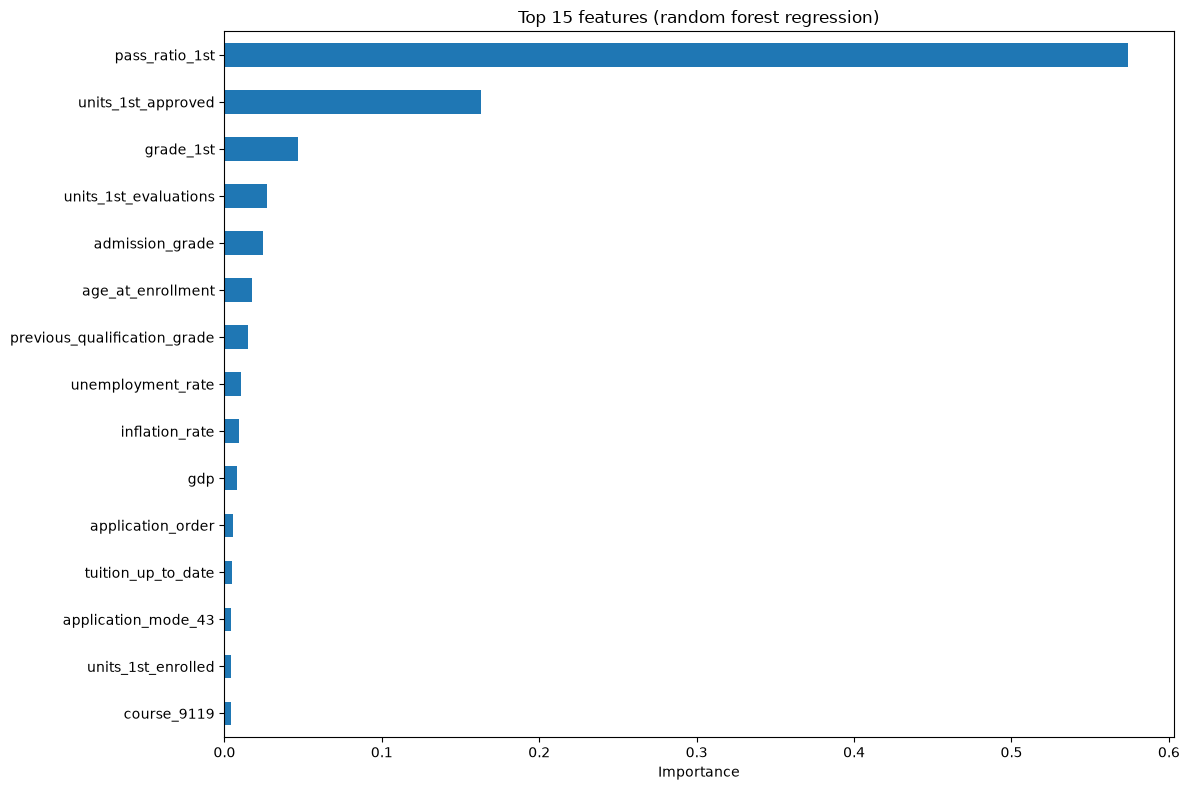

In [8]:
feat_imp = pd.Series(rf_reg.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(12, 8))
feat_imp.head(15).plot(kind="barh")
plt.title("Top 15 features (random forest regression)")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Predicted vs actual (Lasso)

The vertical line at 0 corresponds to students whose second-semester average is 0; they account for the largest errors.

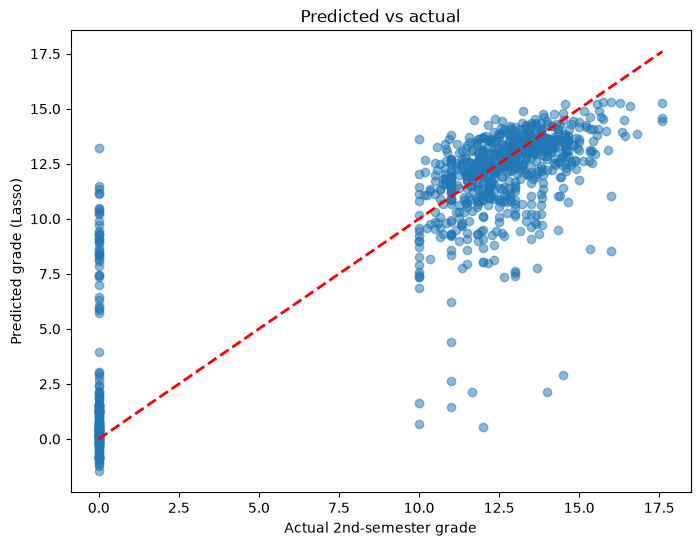

In [9]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_lasso, alpha=0.5)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "r--", lw=2)
plt.xlabel("Actual 2nd-semester grade")
plt.ylabel("Predicted grade (Lasso)")
plt.title("Predicted vs actual")
plt.savefig(FIGURES / "regression_pred_vs_actual.png", dpi=120, bbox_inches="tight")
plt.show()